# Galactic Tide

This notebook integrates an Oort-cloud-like test particle with the REBOUNDx `galactic_tide` force, records its orbit, and compares the numerical perihelion-rate evolution with the secular vertical-tide prediction.

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import rebound
import reboundx

Myr = 1e6
Gyr = 1e9
PC_IN_AU = 206264.80624538
RHO = 0.1  # set local galactic density (unit: M_sun / pc^3)
OMEGA = 26.0  # set galactic angular velocity (unit: km/s/kpc)

SOUTH_GALACTIC_POLE = np.array([ 8.6766334362782760e-01,  3.5360952239719772e-04, -4.9715208647342957e-01])
NORTH_GALACTIC_POLE = -SOUTH_GALACTIC_POLE

def make_simulation(horizontal_tides=1):
    sim = rebound.Simulation()
    sim.units = ("yr", "AU", "Msun")
    sim.add(m=1)
    sim.N_active = 1
    a_comet = 10000.0
    pomega = np.pi
    omega = np.pi
    Omega = pomega - omega
    sim.add(m=0.0, a=a_comet, e=1.0 - 25.0 / a_comet, inc=np.deg2rad(0), omega=omega, Omega=Omega)
    sim.move_to_com()

    sim.integrator = "whfast"
    sim.dt = 2000.0
    rebx = reboundx.Extras(sim)
    tides = rebx.load_force("galactic_tide")
    tides.params["gt_rho"] = RHO
    tides.params["gt_omega"] = OMEGA

    # horizontal tides are turned on by default, if you want to turn them off, you can set:
    tides.params["gt_horizontal"] = horizontal_tides

    rebx.add_force(tides)
    return sim, rebx

In [29]:
def galactic_angles(sim):
    d = sim.particles[1] - sim.particles[0]
    r_vec = np.array(d.xyz)
    v_vec = np.array(d.vxyz)

    h_vec = np.cross(r_vec, v_vec)
    r_hat = r_vec / np.linalg.norm(r_vec)
    h_hat = h_vec / np.linalg.norm(h_vec)

    mu = sim.G * (sim.particles[0].m + sim.particles[1].m)
    P_vec = np.cross(v_vec, h_vec) / mu - r_hat
    P_hat = P_vec / np.linalg.norm(P_vec)

    inc_g = np.arccos(np.clip(np.dot(h_hat, NORTH_GALACTIC_POLE), -1.0, 1.0))

    n_vec = np.cross(NORTH_GALACTIC_POLE, h_hat)
    n_hat = n_vec / np.linalg.norm(n_vec)

    omega_g = np.arctan2(np.dot(h_hat, np.cross(n_hat, P_hat)), np.dot(n_hat, P_hat)) % (2 * np.pi)

    return inc_g, omega_g


def integrate_tides(t_end=4.5 * Gyr, output_interval=1 * Myr, horizontal_tides=1):
    sim, rebx = make_simulation(horizontal_tides=horizontal_tides)
    sample_times = np.arange(0.0, t_end + output_interval, output_interval)
    hist = np.empty((len(sample_times), 7))

    for index, sample_time in enumerate(sample_times):
        sim.integrate(sample_time, exact_finish_time=0)
        orbit = sim.orbits(primary=sim.com())[0]
        inc_g, omega_g = galactic_angles(sim)
        hist[index] = (sim.t, orbit.a, orbit.a * (1.0 - orbit.e), orbit.inc, orbit.omega, inc_g, omega_g)

    return {
        "time": hist[:, 0],
        "a": hist[:, 1],
        "q": hist[:, 2],
        "inc": hist[:, 3],
        "omega": hist[:, 4],
        "inc_g": hist[:, 5],
        "omega_g": hist[:, 6],
    }, sim


# hist_nohorizontal, sim = integrate_tides(horizontal_tides=0)
hist_horizontal, sim = integrate_tides(horizontal_tides=1)
hist = hist_horizontal

In [30]:
def vertical_tide_analytical(a, q, inc_g, omega_g, M_sun, G):
    """Secular dq/dt from the vertical Galactic tide, in AU per year."""
    return (-10.0* np.pi * G * RHO / PC_IN_AU**3 * a**2 * np.sqrt(q) / np.sqrt(2.0 * G * M_sun) * np.sin(inc_g) ** 2 * np.sin(2.0 * omega_g))


time_myr = hist["time"] / Myr
analytical_q_dot = vertical_tide_analytical(hist["a"], hist["q"], hist["inc_g"], hist["omega_g"], sim.particles[0].m, sim.G) * Myr
numerical_q_dot = np.gradient(hist["q"], hist["time"]) * Myr

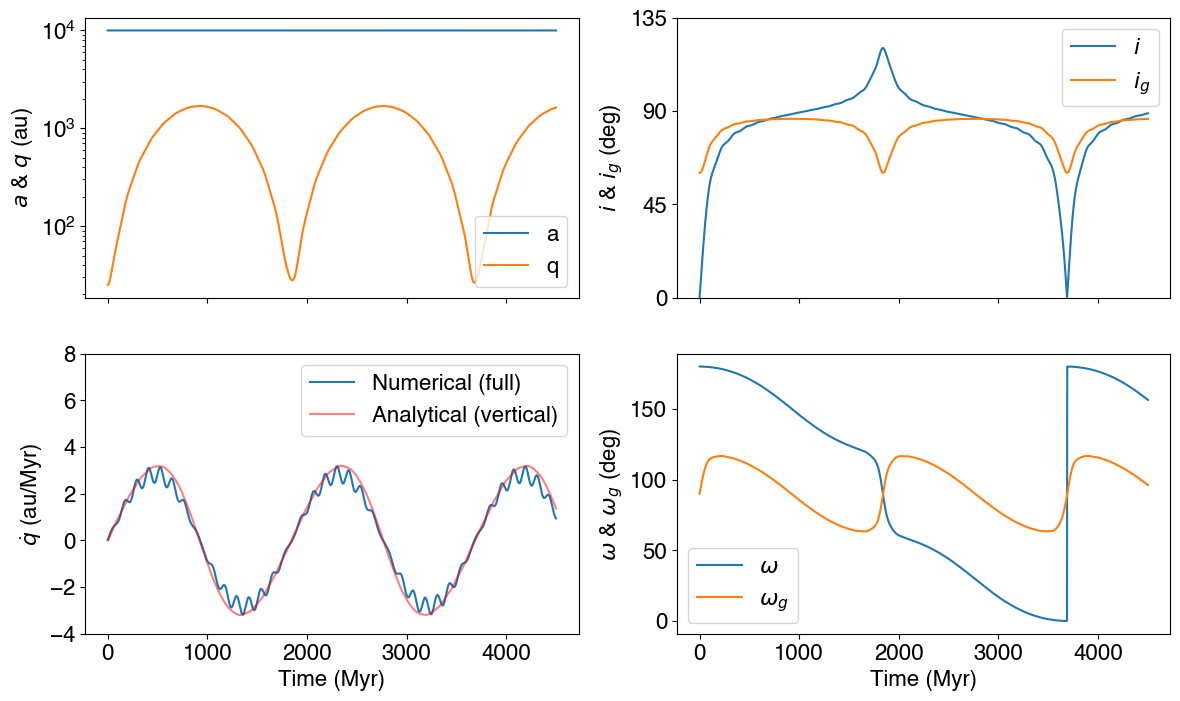

In [31]:
import orbitplotkit as opk
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes[0][0].plot(time_myr, hist_horizontal["a"], label="a")
axes[0][0].plot(time_myr, hist_horizontal["q"], label="q")
axes[0][0].set_yscale("log")
axes[0][0].set_ylabel(rf"$a$ & $q$ (au)")
axes[0][0].legend()

axes[1][0].plot(time_myr[:-1], numerical_q_dot[:-1], ms=2, label="Numerical (full)")
axes[1][0].plot(time_myr, analytical_q_dot, label="Analytical (vertical)", color="red", alpha=0.5)
axes[1][0].set_ylabel(r"$\dot{q}$ (au/Myr)")
axes[1][0].set_ylim([-4, 8])
axes[1][0].set_xlabel("Time (Myr)")
axes[1][0].legend()

axes[0][1].plot(time_myr, np.rad2deg(hist["inc"]), label=r"$i$")
axes[0][1].plot(time_myr, np.rad2deg(hist["inc_g"]), label=r"$i_g$")
axes[0][1].set_ylabel(r"$i$ & $i_g$ (deg)")
axes[0][1].set_ylim([0, 135])
axes[0][1].set_yticks([0, 45, 90, 135])
axes[0][1].legend()

axes[1][1].plot(time_myr, np.rad2deg(hist["omega"]), label=r"$\omega$")
axes[1][1].plot(time_myr, np.rad2deg(hist["omega_g"]), label=r"$\omega_g$")
axes[1][1].set_xlabel("Time (Myr)")
axes[1][1].set_ylabel(r"$\omega$ & $\omega_g$ (deg)")
axes[1][1].legend()

plt.show()
fig.tight_layout()